# 03 — Coronagraph & contrast

The coronagraph sets the ESC apart from a wide-field imager. Three knobs drive it:

- **`raw_dh_contrast`** — the raw dark-hole contrast; sets the residual *speckle* rate.
- **`ppgain`** — post-processing gain; sets the systematic noise *floor* (`M = speckle / ppgain`).
- **`separation`** — planet separation (arcsec); sets the off-axis (FPM) throughput.

> **Requirements:** this tutorial needs the `config_um` and `config_stp_esc` config repos and an editable install (`pip install -e .`). It uses the **UM 3 m** configuration (the supported path).

In [1]:
import astropy.units as u
from esc_etc import Simulation, use_lazuli_style, plot_offaxis_throughput
use_lazuli_style()

sim = Simulation.from_default(hoststarmag=-0.353, planetdeltamag=20,
                              contrast=1e-8, ppgain=10, separation=0.4)
T, FT = 3600 * u.s, 100 * u.s

## 1. Raw dark-hole contrast

Smaller contrast -> fewer residual speckles -> higher SNR. We update the coronagraph in place and recompute.

In [2]:
snrs = []
for cval in [1e-7, 1e-8, 1e-9]:
    sim.coronagraph.update(raw_dh_contrast=cval)
    val = sim.get_snr(total_time=T, frame_time=FT)['snr']
    snrs.append(val)
    print(f'  contrast {cval:.0e}: SNR={val:.3f}')
sim.coronagraph.reset()
assert snrs[0] < snrs[1] < snrs[2]
print('sanity OK: smaller contrast -> higher SNR')

  contrast 1e-07: SNR=0.997
  contrast 1e-08: SNR=8.922
  contrast 1e-09: SNR=20.458
sanity OK: smaller contrast -> higher SNR


## 2. Post-processing gain (`ppgain`)

Higher `ppgain` suppresses the speckle floor `M`, raising SNR in the systematics-limited regime.

In [3]:
pp = []
for g in [1, 10, 100]:
    sim.coronagraph.update(ppgain=g)
    val = sim.get_snr(total_time=T, frame_time=FT)['snr']
    pp.append(val)
    print(f'  ppgain={g:4d}: SNR={val:.3f}')
sim.coronagraph.reset()
assert pp[0] < pp[1] < pp[2]
print('sanity OK: higher ppgain -> higher SNR')

  ppgain=   1: SNR=0.999
  ppgain=  10: SNR=8.922
  ppgain= 100: SNR=19.381
sanity OK: higher ppgain -> higher SNR


## 3. Separation and off-axis throughput

The focal-plane mask suppresses light near the star, so the planet's off-axis throughput rises with separation.

In [4]:
for sep in [0.1, 0.2, 0.4]:
    k = sim.coronagraph.off_axis_throughput(sep)
    print(f'  sep={sep} arcsec -> off-axis throughput {k:.3f}')

assert abs(sim.coronagraph.off_axis_throughput(0.4) - 0.543) < 0.02
print('sanity OK: off-axis throughput at 0.4 arcsec ~ 0.543')

  sep=0.1 arcsec -> off-axis throughput 0.100
  sep=0.2 arcsec -> off-axis throughput 0.345
  sep=0.4 arcsec -> off-axis throughput 0.543
sanity OK: off-axis throughput at 0.4 arcsec ~ 0.543


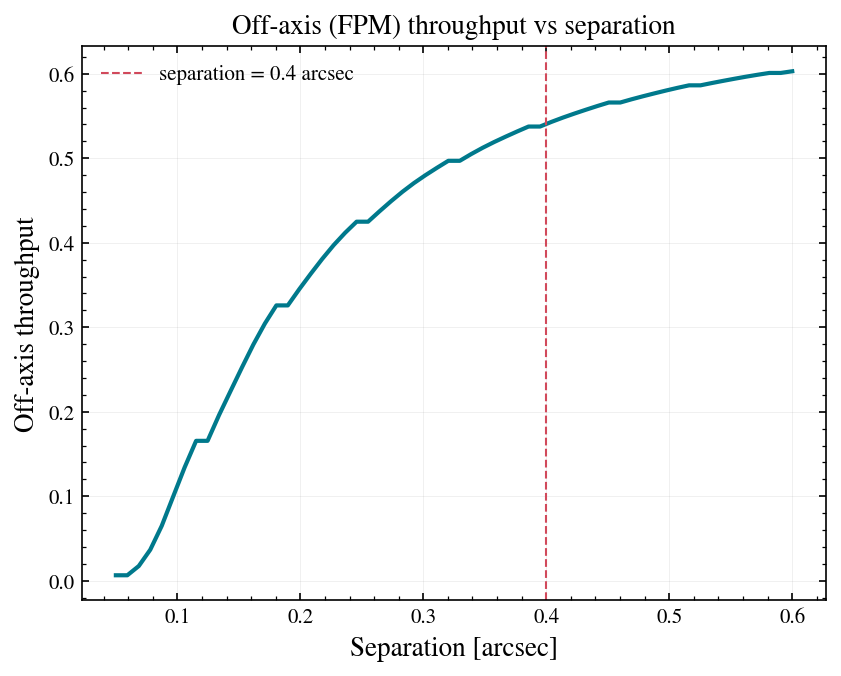

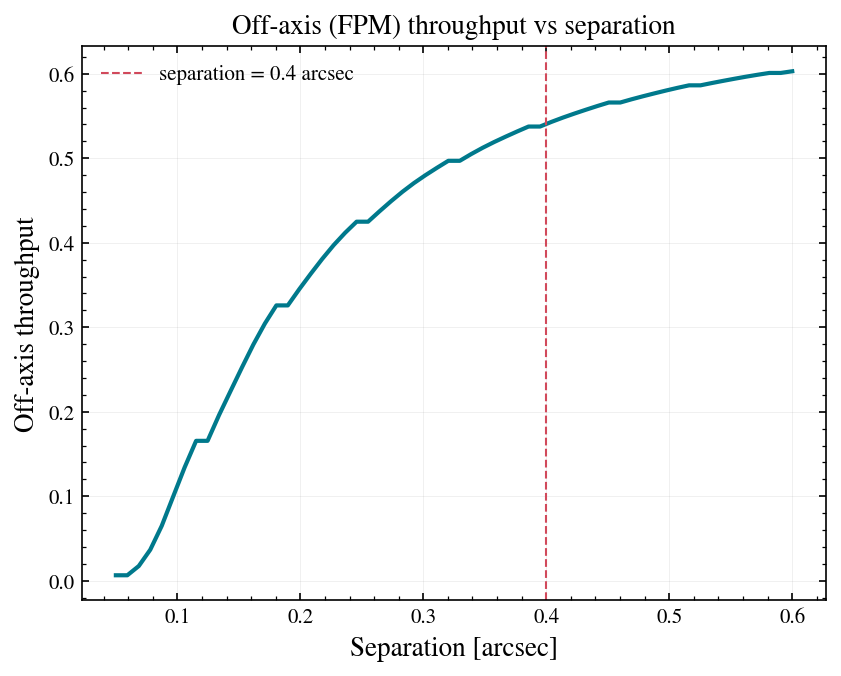

In [5]:
fig, ax = plot_offaxis_throughput(sim)
ax.set_title('Off-axis (FPM) throughput vs separation')
fig

## What you learned

- `raw_dh_contrast`, `ppgain`, and `separation` are the coronagraph knobs.
- Smaller contrast and higher ppgain both raise SNR; separation sets off-axis throughput.
- `plot_offaxis_throughput` shows the FPM transmission curve.

**Next:** notebook 04 covers integration time, the SNR-vs-time curve, and saturation.